# Geometry of loss landscapes with and without a skip connection in PyTorch

We fit noisy observations of g(x) = 0.7 cos(2.5x) + 0.35x, with independent Gaussian noise of standard deviation 0.08.

Both networks have three ReLU hidden layers of widths (4, 4, 4), a linear output, and 53 trainable parameters. The residual model adds the first hidden representation to the third: h3 = ReLU(layer3(h2)) + h1. This identity skip has no trainable parameters.

PyTorch provides the automatic backpropagation and full-batch SGD. Both models start from identical weights, using seeded PyTorch default initialisation, and train for 2800 steps with learning rate 0.03. The loss is half the mean squared error. CPU float64 is used for accurate curvature calculations.

Hessians are computed by automatic differentiation rather than finite differences.

In [2]:
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.func import functional_call
from torch.nn.utils import parameters_to_vector
from sklearn.decomposition import PCA

# CPU float64 keeps curvature calculations accurate and reproducible.
dtype = torch.float64
# Make a clean curve, then add repeatable noise to create training data.
Xt = torch.linspace(-2, 2, 101, dtype=dtype).reshape(-1, 1)
clean_t = 0.7 * torch.cos(2.5 * Xt) + 0.35 * Xt
noise_generator = torch.Generator().manual_seed(12)
yt = clean_t + 0.08 * torch.randn(Xt.shape, generator=noise_generator, dtype=dtype)
x = Xt[:, 0].numpy()
clean = clean_t[:, 0].numpy()
y = yt.numpy()

# Build two networks with the same layers; one can add a shortcut.
class MLP(nn.Module):
    def __init__(self, skip=False):
        super().__init__()
        self.skip = skip
        self.layers = nn.ModuleList([
            nn.Linear(1, 4), nn.Linear(4, 4),
            nn.Linear(4, 4), nn.Linear(4, 1),
        ])
        self.double()

    def forward(self, inputs, return_preactivations=False):
        z1 = self.layers[0](inputs)
        h1 = torch.relu(z1)
        z2 = self.layers[1](h1)
        h2 = torch.relu(z2)
        z3 = self.layers[2](h2)
        h3 = torch.relu(z3) + self.skip * h1
        pred = self.layers[3](h3)
        return (pred, (z1, z2, z3)) if return_preactivations else pred

    def forward_with_parameters(self, theta, inputs, return_preactivations=False):

        # functional_call needs to know which numbers belong to which parameter, and their required shapes. It expects a dictionary. Hence, we write a dictionary params = {}. We use the method self.named_parameters
        params = {}
        offset = 0
        for name, parameter in self.named_parameters():
            size = parameter.numel()
            params[name] = theta[offset:offset + size].reshape(parameter.shape)
            offset += size

        # Uses the seperate pytorch function functional_call(self) which essentially does what self.forward does by evaluating the model, but at our dictionary params coming from theta. It also remembers theta for autograd
        return functional_call(
            self, params, (inputs,),
            {'return_preactivations': return_preactivations})

# Use PyTorchs default layer initialisation and share it between models.
torch.manual_seed(42)
base = MLP()
models = [copy.deepcopy(base), copy.deepcopy(base)]
models[1].skip = True

# Measure how far predictions are from the observed data.
def loss(pred):
    return 0.5 * nn.functional.mse_loss(pred, yt)

# Measure the error at any chosen weights, including points outside training.
def loss_at(theta, skip):
    pred = models[skip].forward_with_parameters(theta, Xt)
    return loss(pred)

# Return a plain number for plotting the height of the loss surface.
def Loss(theta, skip):
    with torch.no_grad():
        return loss_at(torch.as_tensor(theta, dtype=dtype), skip).item()

Plain: 53 parameters, final loss 0.039998427
With skip: 53 parameters, final loss 0.015882581


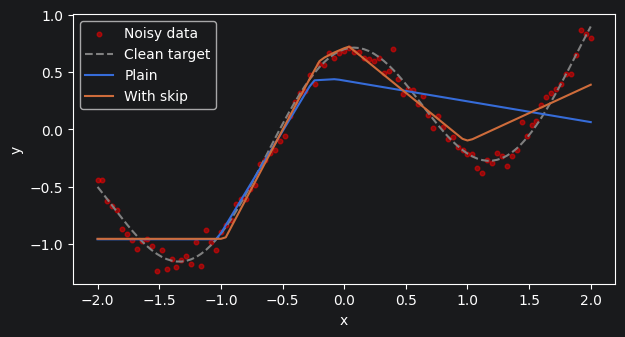

In [3]:
# Train both models from the same starting weights.
labels = ['Plain', 'With skip']
paths = []
for model in models:
    model.load_state_dict(base.state_dict())  # rerunning starts from the same weights
    optimiser = torch.optim.SGD(model.parameters(), lr=0.03)
    path = [parameters_to_vector(model.parameters()).detach().numpy().copy()]
    for _ in range(2800):
        # Clear old gradients, calculate new ones, then take one learning step.
        optimiser.zero_grad()
        loss(model(Xt)).backward()
        optimiser.step()
        # Save the new weights so we can trace the route taken during training.
        path.append(parameters_to_vector(model.parameters()).detach().numpy().copy())
    paths.append(np.array(path))

# Compare the final fitted curves with the data.
plt.figure(figsize=(7, 3.5))
plt.scatter(x, y[:, 0], color='red', s=11, alpha=0.5, label='Noisy data')
plt.plot(x, clean, '--', color='grey', label='Clean target')
for skip, path in enumerate(paths):
    with torch.no_grad():
        #extract a numpy array of predicted values against the linspace Xt
        prediction = models[skip].forward_with_parameters(
            torch.as_tensor(path[-1], dtype=dtype), Xt).numpy()[:, 0]

    plt.plot(x, prediction, label=labels[skip])

    print(f'{labels[skip]}: {sum(p.numel() for p in models[skip].parameters())} parameters, '
          f'final loss {Loss(path[-1], skip):.9f}')

plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

## Compare the loss surfaces

[Li et al., Visualizing the Loss Landscape of Neural Nets](https://arxiv.org/abs/1712.09913) use low-dimensional slices and Hessian eigenvalues to study neural networks.

We use each run's checkpoint at epoch=epoch as its centre and the same two unit directions for both plots: the minimum- and maximum-eigenvalue directions of the plain model's Hessian. This selected example illustrates local behaviour rather than a general guarantee about skip connections.

The first figure shows the actual training loss. The second subtracts the tangent plane: L(theta + d) - L(theta) - gradient(L)(theta) dot d. Subtracting an affine function preserves curvature and the midpoint inequality. A negative midpoint gap means the average endpoint loss is below the centre loss.

PyTorch differentiates the loss twice to compute the local Hessian. Away from zero preactivations, ReLU masks are locally constant. We reject checkpoints at a ReLU kink, where a classical Hessian is undefined. The plotted loss uses ordinary ReLU, so masks can change across the grid.

In [4]:
# Check whether any hidden neuron is close to the ReLU switching boundary.
def near_relu_kink(theta, skip, tolerance=1e-12):
    with torch.no_grad():
        _, preactivations = models[skip].forward_with_parameters(
            torch.as_tensor(theta, dtype=dtype), Xt,
            return_preactivations=True)
        return any(
            torch.any(zi.abs() < tolerance).item()
            for zi in preactivations
        )

# Find which direction each weight would move to increase the error.
def gradient_at_parameters(theta, skip):
    theta = torch.tensor(theta, dtype=dtype, requires_grad=True)
    return torch.autograd.grad(loss_at(theta, skip), theta)[0].detach().numpy()

def hessian(theta, skip):
    # A classical Hessian is undefined at a ReLU kink.
    if near_relu_kink(theta, skip):
        return None
    # Differentiate twice to measure how the loss bends around these weights.
    H = torch.autograd.functional.hessian(
        lambda t: loss_at(t, skip), torch.tensor(theta, dtype=dtype))
    return H.detach().numpy()

def loss_grid(a, b, centre, directions, skip):
    # Try a grid of nearby weights and record the loss at every point.
    A, B = np.meshgrid(a, b)
    Z = np.array([
        Loss(centre + s * directions[0] + t * directions[1], skip)
        for s, t in zip(A.ravel(), B.ravel())
    ])
    return A, B, Z.reshape(A.shape)

Plain  |  loss 0.126546 to 0.126478 at next step  |  gradient norm 0.0477  |  midpoint gap -0.0023
With skip  |  loss 0.068958 to 0.068825 at next step  |  gradient norm 0.0672  |  midpoint gap +0.0064


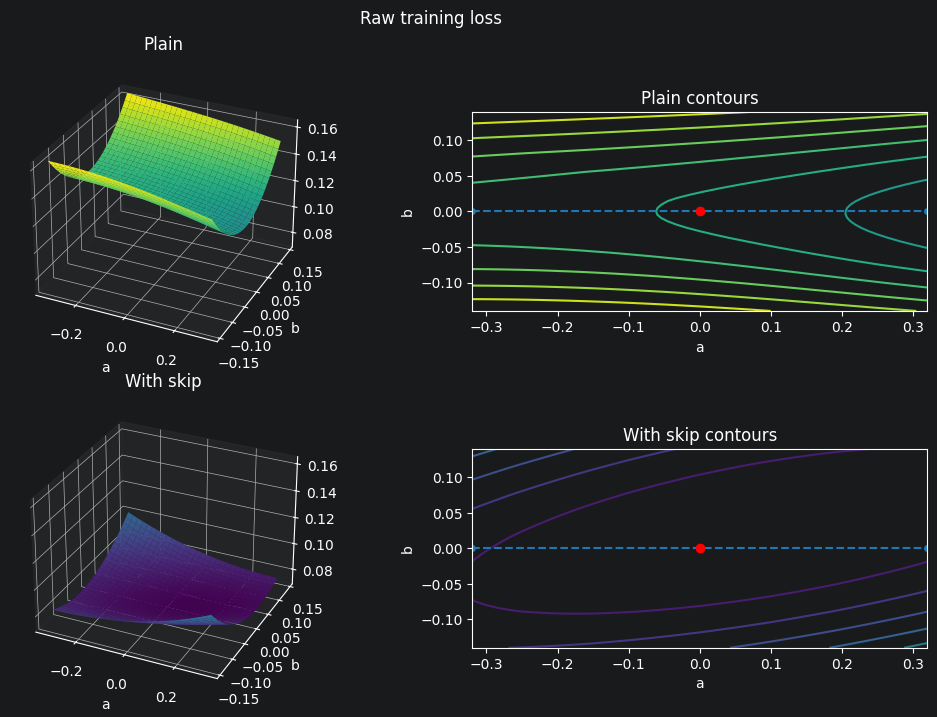

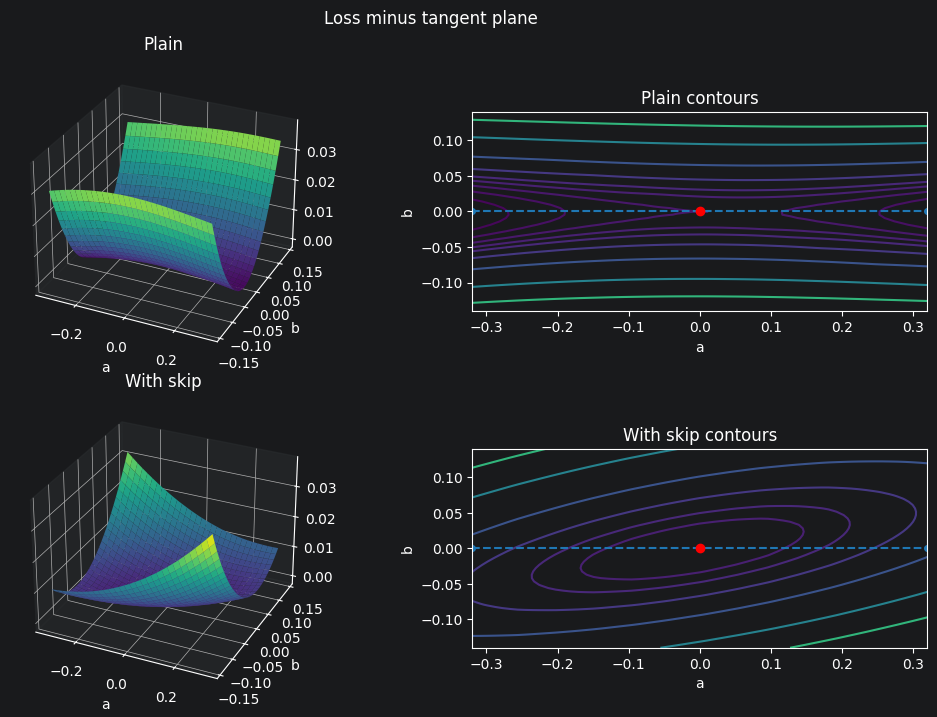

In [8]:
# Pick a saved training step and two directions through parameter space.
epoch = 500

centres = [path[epoch] for path in paths]
_, vectors = np.linalg.eigh(hessian(centres[0], skip=0))
directions = vectors[:, [0, -1]].T
a, b = np.linspace(-0.32, 0.32, 61), np.linspace(-0.14, 0.14, 61)

raw, detrended = [], []
for skip, centre in enumerate(centres):
    A, B, Z = loss_grid(a, b, centre, directions, skip)
    value = Loss(centre, skip)
    grad = gradient_at_parameters(centre, skip)
    slope = directions @ grad
    raw.append(Z)
    # Remove the local slope to make the bending easier to see.
    detrended.append(Z - value - slope[0] * A - slope[1] * B)
    step = a[-1] * directions[0]
    gap = (Loss(centre + step, skip) + Loss(centre - step, skip)) / 2 - value
    next_loss = Loss(paths[skip][epoch + 1], skip)
    print(f"{labels[skip]}  |  loss {value:.6f} to {next_loss:.6f} at next step"
          f"  |  gradient norm {np.linalg.norm(grad):.4f}  |  midpoint gap {gap:+.4f}")

curvature_levels = [-0.004, -0.002, -0.001, 0, 0.001, 0.002, 0.004, 0.008, 0.016, 0.025]
raw_levels = np.linspace(np.min(raw), np.max(raw), 14)[1:-1]

# Draw the surfaces as both 3D hills and contour maps.
for surfaces, levels, title in [(raw, raw_levels, "Raw training loss"),
                                 (detrended, curvature_levels, "Loss minus tangent plane")]:
    lo, hi = np.min(surfaces), np.max(surfaces)
    fig = plt.figure(figsize=(10, 7), constrained_layout=True)
    fig.suptitle(title)
    for i, Z in enumerate(surfaces):
        ax = fig.add_subplot(2, 2, 2*i + 1, projection="3d")
        ax.plot_surface(A, B, Z, cmap="viridis", vmin=lo, vmax=hi, edgecolor="none")
        ax.view_init(elev=29, azim=-65)
        ax.set(xlabel="a", ylabel="b", zlim=(lo, hi), title=labels[i])

        ax = fig.add_subplot(2, 2, 2*i + 2)
        ax.contour(A, B, Z, levels=levels, cmap="viridis", vmin=lo, vmax=hi)
        ax.plot([a[0], a[-1]], [0, 0], "o--", color="tab:blue", markersize=4)
        ax.scatter(0, 0, color="red", zorder=3)
        ax.set(xlabel="a", ylabel="b", title=labels[i] + " contours", aspect="equal")
    plt.show()

## Check curvature in the full parameter space

The extreme eigenvalues of the full Hessian give the smallest and largest second directional derivatives over all unit directions. The Hessian of the plotted slice is $D H D^	op$, where $D$ contains the two directions as rows. A positive smallest eigenvalue on the slice says it bends upwards locally in both plotted directions. A negative smallest full eigenvalue still gives a direction of negative curvature.

The results below describe this particular initialisation and checkpoint; a skip connection does not guarantee positive curvature. The ratio $\max(0,-\lambda_{\min})/\lambda_{\max}$, when $\lambda_{\max}>0$, compares negative curvature to positive curvature in these parameter coordinates. The epoch plots put the selected comparison in the context of each training run

Incomplete..

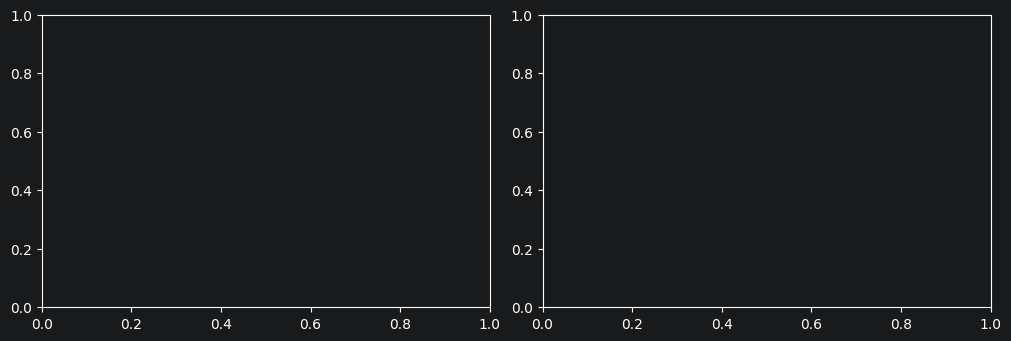

In [9]:
# Track the strongest upward and downward bending during training.
checkpoints = np.arange(0, len(paths[0]), 50)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), constrained_layout=True)
